# La matemática de los optimizadores

Un optimizador recibe el gradiente y decide cómo mover los parámetros. Todos parten de la misma regla, $\theta \leftarrow \theta - \eta \, g$, y le agregan memoria: del gradiente pasado (momento), de su tamaño (RMSprop) o de ambos (Adam).

Para cada optimizador de `torch.optim` este notebook escribe sus ecuaciones tal como las implementa PyTorch, explica qué problema resuelven, y las reimplementa a mano comprobando que la trayectoria coincide.

**Contenido**

1. El problema de prueba
2. `SGD`
3. `weight_decay`: regularización L2
4. Momento
5. Por qué el momento acelera
6. Momento de Nesterov
7. `RMSprop`: una tasa por parámetro
8. `Adam`
9. La corrección de sesgo de Adam
10. Adam no depende de la escala del gradiente
11. `AdamW`: decaimiento de pesos desacoplado
12. Comparación en un valle angosto
13. Resumen y ejercicios

In [1]:
import math

import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)
torch.set_default_dtype(torch.float64)
print("Versión de PyTorch:", torch.__version__)

Versión de PyTorch: 2.11.0+cpu


## 1. El problema de prueba

Usamos un problema de mínimos cuadrados con 5 parámetros, $L(\theta) = \frac{1}{N} \lVert A\theta - y \rVert^2$, cuyo gradiente se conoce en forma cerrada (deducido en `03-optimalidad`):

$$g = \nabla L(\theta) = \frac{2}{N} A^\top (A\theta - y)$$

Así las versiones a mano no usan autograd en absoluto: solo la fórmula del gradiente y las ecuaciones del optimizador.

Dos funciones auxiliares hacen la comparación. `con_pytorch` corre un optimizador de `torch.optim` y devuelve los parámetros finales. `comparar` mide la diferencia con el resultado a mano.

In [2]:
N = 20
A = torch.randn(N, 5)
y = torch.randn(N)
theta_inicial = torch.randn(5)


def perdida(theta):
    return ((A @ theta - y) ** 2).mean()


def gradiente(theta):
    return 2 / N * A.T @ (A @ theta - y)


def con_pytorch(crear_optimizador, pasos=50, funcion=perdida):
    theta = theta_inicial.clone().requires_grad_(True)
    optimizador = crear_optimizador([theta])
    for _ in range(pasos):
        optimizador.zero_grad()
        funcion(theta).backward()
        optimizador.step()
    return theta.detach()


def comparar(nombre, a_mano, pytorch):
    diferencia = (a_mano - pytorch).abs().max().item()
    print(f"{nombre:28s} diferencia máxima = {diferencia:.1e}   ¿coinciden? {torch.allclose(a_mano, pytorch)}")

## 2. `SGD`

La regla base, sin memoria:

$$\theta_{t+1} = \theta_t - \eta \, g_t$$

Como se vio en `02-descenso-de-gradiente`, el nombre `SGD` describe cómo se usa (con lotes al azar) y no lo que hace el optimizador, que es aplicar esta resta al gradiente que encuentre.

In [3]:
def sgd_a_mano(lr, pasos=50):
    theta = theta_inicial.clone()
    for _ in range(pasos):
        theta = theta - lr * gradiente(theta)
    return theta


comparar("SGD", sgd_a_mano(lr=0.05), con_pytorch(lambda p: torch.optim.SGD(p, lr=0.05)))

SGD                          diferencia máxima = 2.8e-17   ¿coinciden? True


## 3. `weight_decay`: regularización L2

Con `weight_decay` igual a $\lambda$, PyTorch le suma al gradiente un término proporcional al propio parámetro antes de actualizar:

$$g_t \leftarrow g_t + \lambda \, \theta_t$$

**Justificación.** Ese término es el gradiente de una penalización cuadrática. Si a la pérdida se le suma $\frac{\lambda}{2} \lVert \theta \rVert^2$, su gradiente gana exactamente $\lambda \theta$:

$$\nabla_\theta \left( L(\theta) + \frac{\lambda}{2} \lVert \theta \rVert^2 \right) = \nabla L(\theta) + \lambda \, \theta$$

Así que `weight_decay` es **regularización L2** sin tener que escribirla en la pérdida. El nombre *decaimiento de pesos* viene de reordenar la actualización:

$$\theta_{t+1} = \theta_t - \eta (g_t + \lambda \theta_t) = (1 - \eta \lambda) \, \theta_t - \eta \, g_t$$

En cada paso los parámetros se encogen primero por el factor $(1 - \eta\lambda)$ y luego se mueven según el gradiente. La penalización favorece parámetros pequeños, lo que limita la capacidad del modelo de ajustarse al ruido de los datos.

Comprobamos las dos lecturas: sumar $\lambda\theta$ al gradiente, y agregar la penalización a la pérdida.

In [4]:
lam = 0.1


def sgd_con_decaimiento_a_mano(lr, lam, pasos=50):
    theta = theta_inicial.clone()
    for _ in range(pasos):
        g = gradiente(theta) + lam * theta
        theta = theta - lr * g
    return theta


con_decaimiento = con_pytorch(lambda p: torch.optim.SGD(p, lr=0.05, weight_decay=lam))
con_penalizacion = con_pytorch(lambda p: torch.optim.SGD(p, lr=0.05),
                               funcion=lambda th: perdida(th) + lam / 2 * (th ** 2).sum())

comparar("SGD + weight_decay", sgd_con_decaimiento_a_mano(0.05, lam), con_decaimiento)
comparar("penalización en la pérdida", con_penalizacion, con_decaimiento)
print(f"\nnorma de θ sin decaimiento: {sgd_a_mano(0.05).norm():.4f}    con decaimiento: {con_decaimiento.norm():.4f}")

SGD + weight_decay           diferencia máxima = 2.8e-17   ¿coinciden? True
penalización en la pérdida   diferencia máxima = 0.0e+00   ¿coinciden? True

norma de θ sin decaimiento: 0.4762    con decaimiento: 0.4537


## 4. Momento

El descenso de gradiente simple olvida todo en cada paso. El **momento** le agrega una velocidad $v$ que acumula los gradientes anteriores. Con `momentum` igual a $\mu$, PyTorch calcula:

$$v_{t+1} = \mu \, v_t + g_t \qquad\qquad \theta_{t+1} = \theta_t - \eta \, v_{t+1}$$

con $v_0 = 0$. La analogía física es una bola que rueda por la superficie de pérdida: el gradiente es la fuerza, $v$ la velocidad, y $\mu$ (típicamente 0.9) hace el papel de la fricción, que determina cuánta velocidad se conserva.

**Qué acumula $v$.** Desarrollando la recurrencia:

$$v_{t+1} = g_t + \mu \, g_{t-1} + \mu^2 g_{t-2} + \mu^3 g_{t-3} + \dots$$

Es una suma de los gradientes pasados con pesos que decaen geométricamente. De ahí salen sus dos efectos:

- **En direcciones donde el gradiente mantiene el signo**, los términos se suman. Si el gradiente fuera constante, $v$ tendería a $g (1 + \mu + \mu^2 + \dots) = \dfrac{g}{1 - \mu}$. Con $\mu = 0.9$ el paso efectivo es hasta **10 veces mayor**.
- **En direcciones donde el gradiente cambia de signo en cada paso**, los términos se cancelan y el paso efectivo se achica.

Es justo lo que hace falta en un valle angosto: avanzar más a lo largo del fondo (gradiente pequeño y consistente) y oscilar menos entre las paredes (gradiente grande y alternante).

*Nota.* En muchos textos el momento se escribe $v_{t+1} = \mu v_t - \eta g_t$, $\theta_{t+1} = \theta_t + v_{t+1}$. Con tasa de aprendizaje constante es la misma trayectoria; solo cambia en qué variable se guarda el factor $\eta$.

In [5]:
def momento_a_mano(lr, mu, pasos=50):
    theta = theta_inicial.clone()
    v = torch.zeros_like(theta)
    for _ in range(pasos):
        v = mu * v + gradiente(theta)
        theta = theta - lr * v
    return theta


comparar("SGD con momento", momento_a_mano(lr=0.02, mu=0.9),
         con_pytorch(lambda p: torch.optim.SGD(p, lr=0.02, momentum=0.9)))

SGD con momento              diferencia máxima = 1.1e-16   ¿coinciden? True


## 5. Por qué el momento acelera

Para funciones cuadráticas la ganancia se puede cuantificar. En `03-optimalidad` vimos que la velocidad del descenso de gradiente depende del número de condición $\kappa = \lambda_{\max} / \lambda_{\min}$ del hessiano: con la mejor tasa fija, la distancia al óptimo se multiplica en cada paso por un factor que, en el peor caso, vale

$$\rho_{\text{GD}} = \frac{\kappa - 1}{\kappa + 1}$$

Con momento, eligiendo de forma óptima la tasa y el coeficiente (resultado de Polyak, 1964),

$$\eta = \frac{4}{\left( \sqrt{\lambda_{\max}} + \sqrt{\lambda_{\min}} \right)^2} \qquad \mu = \left( \frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1} \right)^2$$

el factor pasa a ser, una vez superados los primeros pasos,

$$\rho_{\text{momento}} = \frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}$$

La diferencia es que aparece $\sqrt{\kappa}$ en lugar de $\kappa$. Un problema con $\kappa = 100$ se comporta, con momento, como uno con $\kappa = 10$.

Lo probamos con la pérdida de la neurona sobre las diez entregas sin normalizar, cuyo número de condición es 88:

In [6]:
distancias = torch.tensor([1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 5.5])
tiempos = torch.tensor([7.3, 9.1, 12.4, 14.2, 17.5, 19.0, 22.6, 24.1, 27.4, 29.2])

A_valle = torch.stack([distancias, torch.ones(10)], dim=1)
H = 2 / 10 * A_valle.T @ A_valle
l_min, l_max = torch.linalg.eigvalsh(H)
kappa = (l_max / l_min).item()
optimo = torch.linalg.lstsq(A_valle, tiempos.unsqueeze(1)).solution.squeeze()


def perdida_valle(theta):
    return ((A_valle @ theta - tiempos) ** 2).mean()


def recorrer(crear_optimizador, pasos):
    """Devuelve la trayectoria de (w, b) partiendo de (0, 0)."""
    theta = torch.zeros(2, requires_grad=True)
    optimizador = crear_optimizador([theta])
    trayectoria = [theta.detach().clone()]
    for _ in range(pasos):
        optimizador.zero_grad()
        perdida_valle(theta).backward()
        optimizador.step()
        trayectoria.append(theta.detach().clone())
    return torch.stack(trayectoria)


lr_gd = (2 / (l_max + l_min)).item()
lr_momento = (4 / (l_max.sqrt() + l_min.sqrt()) ** 2).item()
mu_optimo = ((math.sqrt(kappa) - 1) / (math.sqrt(kappa) + 1)) ** 2

print(f"kappa = {kappa:.1f}")
print(f"descenso de gradiente: lr = {lr_gd:.4f}                     factor teórico por paso = {(kappa - 1) / (kappa + 1):.3f}")
print(f"con momento          : lr = {lr_momento:.4f}, momentum = {mu_optimo:.3f}   factor teórico por paso = {(math.sqrt(kappa) - 1) / (math.sqrt(kappa) + 1):.3f}")

kappa = 88.0
descenso de gradiente: lr = 0.0734                     factor teórico por paso = 0.978
con momento          : lr = 0.1212, momentum = 0.652   factor teórico por paso = 0.807


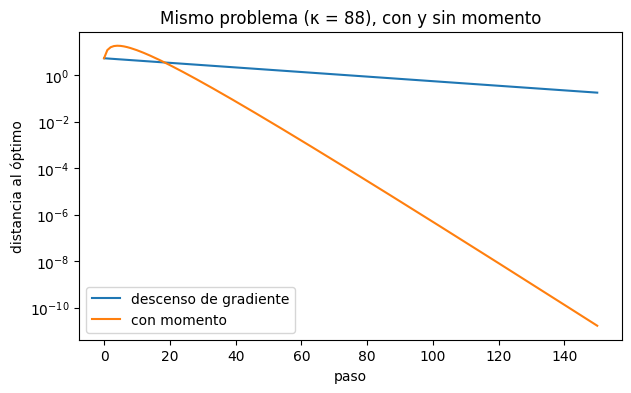

factor medido por paso, descenso de gradiente: 0.978
factor medido por paso, con momento          : 0.824


In [7]:
tray_gd = recorrer(lambda p: torch.optim.SGD(p, lr=lr_gd), pasos=150)
tray_momento = recorrer(lambda p: torch.optim.SGD(p, lr=lr_momento, momentum=mu_optimo), pasos=150)

plt.figure(figsize=(7, 4))
plt.plot((tray_gd - optimo).norm(dim=1), label="descenso de gradiente")
plt.plot((tray_momento - optimo).norm(dim=1), label="con momento")
plt.yscale("log")
plt.xlabel("paso")
plt.ylabel("distancia al óptimo")
plt.title(f"Mismo problema (κ = {kappa:.0f}), con y sin momento")
plt.legend()
plt.show()


def factor_medido(tray, desde=50, hasta=150):
    dist = (tray - optimo).norm(dim=1)
    return (dist[hasta] / dist[desde]).item() ** (1 / (hasta - desde))


print(f"factor medido por paso, descenso de gradiente: {factor_medido(tray_gd):.3f}")
print(f"factor medido por paso, con momento          : {factor_medido(tray_momento, desde=20, hasta=100):.3f}")

Pasado el tramo inicial, en escala logarítmica las dos curvas son rectas: el error se multiplica por un factor constante en cada paso, y la pendiente con momento es mucho más pronunciada. Al principio el momento incluso se aleja del óptimo, porque la velocidad acumulada lo hace pasarse de largo.

El factor medido del descenso de gradiente coincide con la teoría. El del momento queda algo por encima: con los parámetros óptimos el error se comporta como $t \cdot \rho^t$ y no como $\rho^t$ a secas, y ese factor $t$ adicional se nota en una ventana de pocos pasos.

## 6. Momento de Nesterov

Con `nesterov=True`, PyTorch conserva la misma velocidad y cambia la dirección con la que actualiza:

$$v_{t+1} = \mu \, v_t + g_t \qquad\qquad \theta_{t+1} = \theta_t - \eta \, (g_t + \mu \, v_{t+1})$$

La idea original de Nesterov es evaluar el gradiente no en la posición actual, sino en la posición **adonde el momento está por llevar** los parámetros: mirar un paso adelante antes de corregir. La forma de arriba es una reescritura equivalente que permite seguir evaluando el gradiente en $\theta_t$, que es lo que el ciclo de entrenamiento ya tiene calculado. En la práctica reduce las oscilaciones del momento clásico.

In [8]:
def nesterov_a_mano(lr, mu, pasos=50):
    theta = theta_inicial.clone()
    v = torch.zeros_like(theta)
    for _ in range(pasos):
        g = gradiente(theta)
        v = mu * v + g
        theta = theta - lr * (g + mu * v)
    return theta


comparar("SGD con Nesterov", nesterov_a_mano(lr=0.02, mu=0.9),
         con_pytorch(lambda p: torch.optim.SGD(p, lr=0.02, momentum=0.9, nesterov=True)))

SGD con Nesterov             diferencia máxima = 5.6e-17   ¿coinciden? True


## 7. `RMSprop`: una tasa por parámetro

El momento sigue usando una sola tasa de aprendizaje para todos los parámetros. `RMSprop` ataca el problema del valle de otra manera: le da a **cada parámetro su propio tamaño de paso**, inversamente proporcional al tamaño habitual de su gradiente.

Guarda un promedio móvil del **cuadrado** del gradiente, por componente, y divide por su raíz:

$$s_{t+1} = \alpha \, s_t + (1 - \alpha) \, g_t^2 \qquad\qquad \theta_{t+1} = \theta_t - \eta \, \frac{g_t}{\sqrt{s_{t+1}} + \epsilon}$$

Todas las operaciones son elemento a elemento. Los valores por omisión son $\alpha = 0.99$ y $\epsilon = 10^{-8}$.

**Qué significa $s$.** Un promedio móvil exponencial con coeficiente $\alpha$ pondera el pasado con pesos $(1 - \alpha) \alpha^k$, que suman 1. Promedia aproximadamente los últimos $1 / (1 - \alpha)$ valores: unos 100 con $\alpha = 0.99$. Así $\sqrt{s}$ estima la magnitud típica reciente (la raíz cuadrática media, *root mean square*, de ahí el nombre) del gradiente de cada parámetro.

**Efecto.** Al dividir, un parámetro cuyo gradiente es habitualmente grande recibe pasos chicos, y uno con gradiente habitualmente pequeño recibe pasos grandes. El cociente $g / \sqrt{s}$ es del orden de 1 para todos, y el paso de cada parámetro es del orden de $\eta$. Eso compensa las diferencias de escala **entre parámetros**. Como se ve en la sección 12, no corrige un valle que está inclinado respecto de los ejes.

$\epsilon$ evita dividir por cero cuando un gradiente se anula.

In [9]:
def rmsprop_a_mano(lr, alpha=0.99, eps=1e-8, pasos=50):
    theta = theta_inicial.clone()
    s = torch.zeros_like(theta)
    for _ in range(pasos):
        g = gradiente(theta)
        s = alpha * s + (1 - alpha) * g ** 2
        theta = theta - lr * g / (s.sqrt() + eps)
    return theta


comparar("RMSprop", rmsprop_a_mano(lr=0.01), con_pytorch(lambda p: torch.optim.RMSprop(p, lr=0.01)))

RMSprop                      diferencia máxima = 1.1e-16   ¿coinciden? True


## 8. `Adam`

Adam (*adaptive moment estimation*) junta las dos ideas: la dirección suavizada del momento y la escala por parámetro de RMSprop. Mantiene dos promedios móviles:

$$m_t = \beta_1 \, m_{t-1} + (1 - \beta_1) \, g_t \qquad \text{(primer momento: promedio del gradiente)}$$

$$v_t = \beta_2 \, v_{t-1} + (1 - \beta_2) \, g_t^2 \qquad \text{(segundo momento: promedio de su cuadrado)}$$

los corrige (sección siguiente):

$$\hat{m}_t = \frac{m_t}{1 - \beta_1^t} \qquad\qquad \hat{v}_t = \frac{v_t}{1 - \beta_2^t}$$

y actualiza:

$$\theta_t = \theta_{t-1} - \eta \, \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

con $m_0 = v_0 = 0$ y el contador $t$ partiendo en 1. Los valores por omisión son $\eta = 10^{-3}$, $\beta_1 = 0.9$, $\beta_2 = 0.999$ y $\epsilon = 10^{-8}$.

El numerador es una versión suavizada del gradiente (su media reciente) y el denominador es su magnitud típica. El cociente se puede leer como una relación señal a ruido: si el gradiente de un parámetro apunta siempre en la misma dirección y con magnitud parecida, $\lvert \hat{m} \rvert \approx \sqrt{\hat{v}}$ y el paso es cercano a $\eta$; si cambia de signo constantemente, $\hat{m} \approx 0$ y el paso se achica.

In [10]:
def adam_a_mano(lr, beta1=0.9, beta2=0.999, eps=1e-8, pasos=50, grad=gradiente):
    theta = theta_inicial.clone()
    m = torch.zeros_like(theta)
    v = torch.zeros_like(theta)
    for t in range(1, pasos + 1):
        g = grad(theta)
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g ** 2
        m_corregido = m / (1 - beta1 ** t)
        v_corregido = v / (1 - beta2 ** t)
        theta = theta - lr * m_corregido / (v_corregido.sqrt() + eps)
    return theta


comparar("Adam", adam_a_mano(lr=0.05), con_pytorch(lambda p: torch.optim.Adam(p, lr=0.05)))

Adam                         diferencia máxima = 1.7e-16   ¿coinciden? True


## 9. La corrección de sesgo de Adam

Los promedios parten en cero, y eso los sesga hacia cero durante los primeros pasos. En el primer paso, por ejemplo,

$$m_1 = \beta_1 \cdot 0 + (1 - \beta_1) \, g_1 = 0.1 \, g_1$$

que es diez veces menor que el gradiente que pretende estimar. Para $v$ es peor: $v_1 = 0.001 \, g_1^2$.

El tamaño exacto del sesgo se calcula desarrollando la recurrencia:

$$m_t = (1 - \beta_1) \sum_{i=1}^{t} \beta_1^{\,t - i} \, g_i$$

Si los gradientes tienen todos el mismo valor esperado $\mathbb{E}[g]$, y usando la suma geométrica $\sum_{i=1}^{t} \beta_1^{\,t-i} = \dfrac{1 - \beta_1^t}{1 - \beta_1}$:

$$\mathbb{E}[m_t] = (1 - \beta_1) \, \mathbb{E}[g] \cdot \frac{1 - \beta_1^t}{1 - \beta_1} = (1 - \beta_1^t) \, \mathbb{E}[g]$$

El promedio subestima por el factor $(1 - \beta_1^t)$. Dividir por ese factor lo corrige, y eso es $\hat{m}_t$. El mismo argumento con $\beta_2$ da $\hat{v}_t$. Cuando $t$ crece, $\beta^t \to 0$ y la corrección desaparece sola.

Lo vemos con un gradiente constante igual a 1, donde el promedio correcto es 1 desde el primer paso:

In [11]:
beta1 = 0.9
m = 0.0

print(" t     m_t     factor (1 − β₁ᵗ)    m_t corregido")
for t in range(1, 31):
    m = beta1 * m + (1 - beta1) * 1.0           # el gradiente siempre vale 1
    if t in (1, 2, 3, 5, 10, 20, 30):
        print(f"{t:2d}   {m:.4f}       {1 - beta1 ** t:.4f}            {m / (1 - beta1 ** t):.4f}")

 t     m_t     factor (1 − β₁ᵗ)    m_t corregido
 1   0.1000       0.1000            1.0000
 2   0.1900       0.1900            1.0000
 3   0.2710       0.2710            1.0000
 5   0.4095       0.4095            1.0000
10   0.6513       0.6513            1.0000
20   0.8784       0.8784            1.0000
30   0.9576       0.9576            1.0000


Sin corrección, $m_t$ tarda decenas de pasos en acercarse a 1. Con corrección vale 1 en todos los pasos.

Una consecuencia: en el primer paso $\hat{m}_1 = g_1$ y $\hat{v}_1 = g_1^2$, así que la actualización es

$$\Delta\theta = -\eta \, \frac{g_1}{\lvert g_1 \rvert + \epsilon} \approx -\eta \cdot \text{signo}(g_1)$$

**El primer paso de Adam mueve cada parámetro una distancia prácticamente igual a $\eta$**, sea cual sea el tamaño de su gradiente (salvo que sea nulo o tan pequeño como $\epsilon$).

In [12]:
un_paso = adam_a_mano(lr=0.05, pasos=1)

print("gradiente inicial      :", gradiente(theta_inicial))
print("movimiento de cada θ   :", un_paso - theta_inicial)
print("−lr · signo(gradiente) :", -0.05 * torch.sign(gradiente(theta_inicial)))

gradiente inicial      : tensor([ 0.1846, -4.4405, -3.7957, -3.6312,  0.3819])
movimiento de cada θ   : tensor([-0.0500,  0.0500,  0.0500,  0.0500, -0.0500])
−lr · signo(gradiente) : tensor([-0.0500,  0.0500,  0.0500,  0.0500, -0.0500])


## 10. Adam no depende de la escala del gradiente

Si todos los gradientes se multiplican por una constante $c > 0$, entonces $\hat{m}$ se multiplica por $c$ y $\sqrt{\hat{v}}$ también. En el cociente, $c$ se cancela (salvo por el pequeño $\epsilon$):

$$\frac{c \, \hat{m}}{\sqrt{c^2 \hat{v}} + \epsilon} \approx \frac{\hat{m}}{\sqrt{\hat{v}}}$$

La trayectoria de Adam es casi la misma si la pérdida se multiplica por 1000. Con SGD, multiplicar la pérdida por 1000 equivale a multiplicar la tasa de aprendizaje por 1000, lo que normalmente lo hace divergir.

Esta es una de las razones por las que Adam funciona razonablemente con su tasa por omisión en problemas muy distintos, mientras que la tasa de SGD hay que ajustarla para cada caso.

In [13]:
def perdida_por_mil(theta):
    return 1000 * perdida(theta)


adam_normal = con_pytorch(lambda p: torch.optim.Adam(p, lr=0.05))
adam_escalado = con_pytorch(lambda p: torch.optim.Adam(p, lr=0.05), funcion=perdida_por_mil)
sgd_normal = con_pytorch(lambda p: torch.optim.SGD(p, lr=0.05))
sgd_escalado = con_pytorch(lambda p: torch.optim.SGD(p, lr=0.05), funcion=perdida_por_mil)

print(f"Adam: diferencia entre pérdida normal y pérdida × 1000 = {(adam_normal - adam_escalado).abs().max():.1e}")
print(f"SGD : pérdida normal   -> norma de θ = {sgd_normal.norm():.3f}")
print(f"SGD : pérdida × 1000   -> norma de θ = {sgd_escalado.norm():.3e}")

Adam: diferencia entre pérdida normal y pérdida × 1000 = 5.2e-09
SGD : pérdida normal   -> norma de θ = 0.476
SGD : pérdida × 1000   -> norma de θ = 4.252e+117


## 11. `AdamW`: decaimiento de pesos desacoplado

En la sección 3 vimos que, con SGD, sumar $\lambda\theta$ al gradiente (regularización L2) y encoger los parámetros por el factor $(1 - \eta\lambda)$ son la misma operación. Con Adam dejan de serlo.

Si el término $\lambda\theta$ se suma al gradiente (lo que hace `Adam` con `weight_decay`), pasa después por la división por $\sqrt{\hat{v}}$ junto con el resto. Los parámetros con gradientes grandes ven su decaimiento dividido por un número grande, y quedan menos regularizados que los demás. La regularización deja de ser uniforme.

`AdamW` separa las dos cosas. El gradiente que alimenta a $m$ y $v$ es el de la pérdida sin modificar, y el decaimiento se aplica directamente a los parámetros:

$$\theta_t = \underbrace{(1 - \eta \lambda) \, \theta_{t-1}}_{\text{decaimiento}} - \; \eta \, \frac{\hat{m}_t}{\sqrt{\hat{v}_t} + \epsilon}$$

Es el mismo factor $(1 - \eta\lambda)$ que apareció en la sección 3, aplicado por fuera de la parte adaptativa. `AdamW` es hoy la opción habitual cuando se quiere Adam con regularización.

In [14]:
def adamw_a_mano(lr, lam, beta1=0.9, beta2=0.999, eps=1e-8, pasos=50):
    theta = theta_inicial.clone()
    m = torch.zeros_like(theta)
    v = torch.zeros_like(theta)
    for t in range(1, pasos + 1):
        g = gradiente(theta)                        # gradiente de la pérdida, sin el término de decaimiento
        theta = theta * (1 - lr * lam)              # decaimiento directo sobre los parámetros
        m = beta1 * m + (1 - beta1) * g
        v = beta2 * v + (1 - beta2) * g ** 2
        m_corregido = m / (1 - beta1 ** t)
        v_corregido = v / (1 - beta2 ** t)
        theta = theta - lr * m_corregido / (v_corregido.sqrt() + eps)
    return theta


adamw = con_pytorch(lambda p: torch.optim.AdamW(p, lr=0.05, weight_decay=0.1))
adam_l2 = con_pytorch(lambda p: torch.optim.Adam(p, lr=0.05, weight_decay=0.1))

comparar("AdamW", adamw_a_mano(lr=0.05, lam=0.1), adamw)
comparar("Adam con L2 (acoplado)", adam_a_mano(lr=0.05, grad=lambda th: gradiente(th) + 0.1 * th), adam_l2)
print(f"\ndiferencia entre AdamW y Adam con L2: {(adamw - adam_l2).abs().max():.3f}")

AdamW                        diferencia máxima = 4.2e-17   ¿coinciden? True


Adam con L2 (acoplado)       diferencia máxima = 1.7e-16   ¿coinciden? True

diferencia entre AdamW y Adam con L2: 0.008


Las dos versiones a mano coinciden con PyTorch, y entre sí dan resultados distintos: con Adam, sumar $\lambda\theta$ al gradiente y decaer los parámetros no son equivalentes.

## 12. Comparación en un valle angosto

Para cerrar, corremos los cuatro optimizadores sobre el valle de la sección 5 y dibujamos sus caminos. Las tasas de aprendizaje están elegidas a mano para que cada uno funcione razonablemente; no es una comparación de cuál es "mejor", sino de cómo se mueve cada uno.

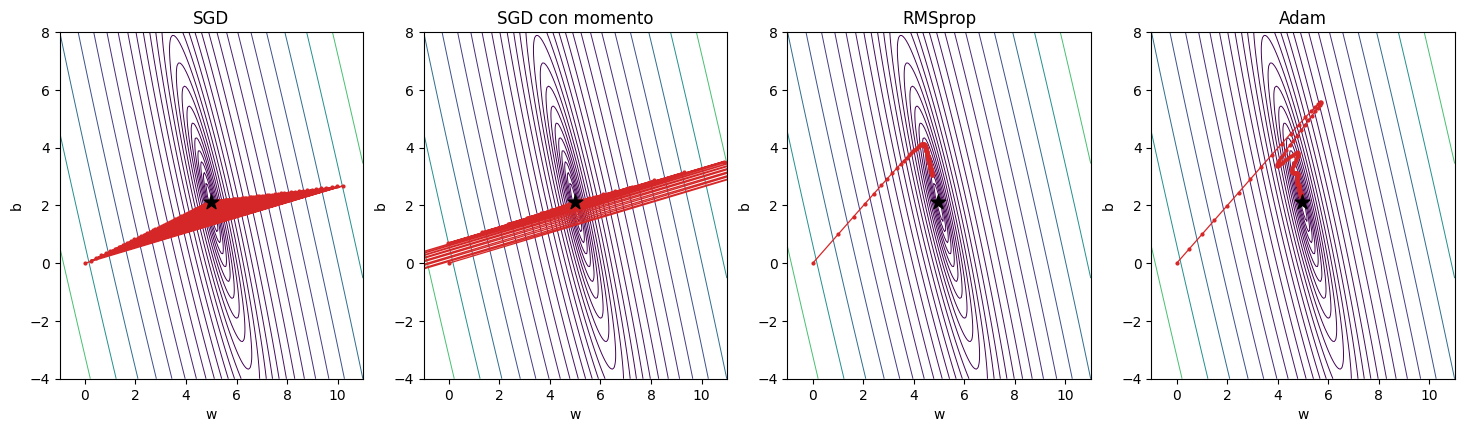

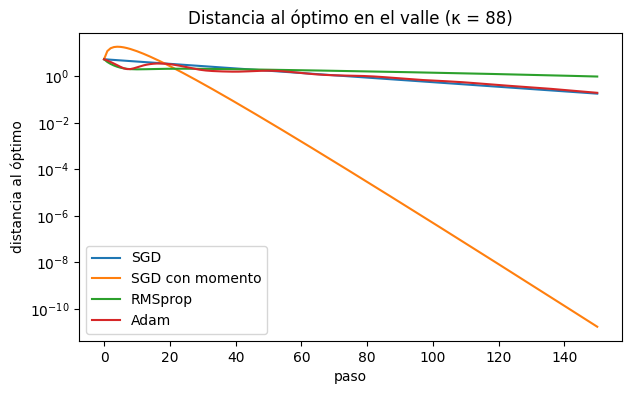

In [15]:
optimizadores = {
    "SGD": lambda p: torch.optim.SGD(p, lr=lr_gd),
    "SGD con momento": lambda p: torch.optim.SGD(p, lr=lr_momento, momentum=mu_optimo),
    "RMSprop": lambda p: torch.optim.RMSprop(p, lr=0.1),
    "Adam": lambda p: torch.optim.Adam(p, lr=0.5),
}
trayectorias = {nombre: recorrer(crear, pasos=150) for nombre, crear in optimizadores.items()}

ws = torch.linspace(-1, 11, 200)
bs = torch.linspace(-4, 8, 200)
GW, GB = torch.meshgrid(ws, bs, indexing="xy")
L = ((GW.unsqueeze(-1) * distancias + GB.unsqueeze(-1) - tiempos) ** 2).mean(dim=-1)
niveles = torch.logspace(torch.log10(L.min()).item(), torch.log10(L.max()).item(), 25).tolist()

fig, ejes = plt.subplots(1, 4, figsize=(18, 4.5))
for eje, (nombre, tray) in zip(ejes, trayectorias.items()):
    eje.contour(GW, GB, L, levels=niveles, cmap="viridis", linewidths=0.7)
    eje.plot(tray[:, 0], tray[:, 1], color="tab:red", marker="o", markersize=2, linewidth=0.9)
    eje.scatter(*optimo, color="black", marker="*", s=120, zorder=3)
    eje.set_xlim(-1, 11)
    eje.set_ylim(-4, 8)
    eje.set_title(nombre)
    eje.set_xlabel("w")
    eje.set_ylabel("b")
plt.show()

plt.figure(figsize=(7, 4))
for nombre, tray in trayectorias.items():
    plt.plot((tray - optimo).norm(dim=1), label=nombre)
plt.yscale("log")
plt.xlabel("paso")
plt.ylabel("distancia al óptimo")
plt.title("Distancia al óptimo en el valle (κ = 88)")
plt.legend()
plt.show()

Lo que muestran los caminos:

- **SGD** rebota de una pared a otra del valle durante todo el recorrido. Con su mejor tasa fija, la oscilación y el avance por el fondo se reducen al mismo ritmo, que es lento.
- **Momento** oscila todavía más al principio (varios puntos caen fuera del gráfico), como una bola con inercia, pero esas oscilaciones se amortiguan rápido y es por lejos el que más se acerca al óptimo.
- **RMSprop y Adam** parten con pasos del mismo tamaño en $w$ y en $b$, sin importar que el gradiente en $w$ sea mucho mayor. Por eso su camino inicial es una diagonal. Después llegan al fondo del valle y lo recorren despacio.

En este problema los métodos adaptativos **no** le ganan a SGD, y vale la pena entender por qué. Una tasa por parámetro equivale a estirar o encoger cada eje por separado. Eso arregla un valle alineado con los ejes, que es el caso de parámetros con escalas muy distintas. Pero este valle está **inclinado**: $w$ y $b$ están correlacionados, porque un cambio en uno se compensa con un cambio en el otro. Ningún reescalado de los ejes endereza una diagonal.

La conclusión práctica es que Adam no reemplaza a la normalización de los datos. Centrar la entrada elimina esa correlación entre $w$ y $b$: el término cruzado del hessiano es proporcional a la media de la entrada, y al centrarla se anula. Con el hessiano diagonal y bien condicionado, SGD ya converge en pocos pasos. El ejercicio 6 explora ese caso.

## 13. Resumen

| Optimizador | Estado que guarda | Actualización |
|---|---|---|
| `SGD` | nada | $\theta \leftarrow \theta - \eta \, g$ |
| `SGD(momentum=μ)` | velocidad $v$ | $v \leftarrow \mu v + g$; $\quad \theta \leftarrow \theta - \eta \, v$ |
| `SGD(nesterov=True)` | velocidad $v$ | $v \leftarrow \mu v + g$; $\quad \theta \leftarrow \theta - \eta (g + \mu v)$ |
| `RMSprop` | promedio de $g^2$ | $s \leftarrow \alpha s + (1 - \alpha) g^2$; $\quad \theta \leftarrow \theta - \eta \, g / (\sqrt{s} + \epsilon)$ |
| `Adam` | promedios de $g$ y de $g^2$ | $\theta \leftarrow \theta - \eta \, \hat{m} / (\sqrt{\hat{v}} + \epsilon)$ |
| `AdamW` | lo mismo que Adam | $\theta \leftarrow (1 - \eta\lambda) \, \theta - \eta \, \hat{m} / (\sqrt{\hat{v}} + \epsilon)$ |

- `weight_decay` en SGD equivale a sumar $\frac{\lambda}{2} \lVert \theta \rVert^2$ a la pérdida.
- El **momento** suma gradientes pasados con pesos geométricos: amplifica las direcciones consistentes hasta $1/(1-\mu)$ veces y cancela las oscilaciones. En cuadráticas cambia $\kappa$ por $\sqrt{\kappa}$ en la velocidad de convergencia.
- **RMSprop** divide cada gradiente por su magnitud típica reciente, dando a cada parámetro su propia tasa efectiva.
- **Adam** combina ambos y corrige el sesgo de partir los promedios en cero. Su paso es casi independiente de la escala del gradiente.
- **AdamW** aplica el decaimiento de pesos fuera de la parte adaptativa.

Una guía práctica habitual: `Adam` o `AdamW` como primera opción, porque funcionan con poca sintonía; `SGD` con momento cuando se dispone de tiempo para ajustar la tasa de aprendizaje y su programación.

## Ejercicios

1. Implementa a mano `SGD` con `momentum=0.9` **y** `weight_decay=0.1` a la vez, y comprueba contra PyTorch. ¿En qué orden se aplican las dos cosas?
2. En la sección 5, usa `momentum=0.9` y `momentum=0.99` con la misma tasa. ¿Qué pasa con la convergencia? Relaciónalo con el valor óptimo que entrega la fórmula.
3. Implementa `Adagrad` a mano: es como RMSprop pero **suma** los cuadrados en lugar de promediarlos, $s \leftarrow s + g^2$. Compara con `torch.optim.Adagrad`. ¿Qué le pasa al tamaño del paso con el tiempo?
4. Quita la corrección de sesgo de `adam_a_mano` y compara los primeros 5 pasos con la versión corregida. ¿Los pasos iniciales son más grandes o más chicos? Explícalo mirando $m_1$ y $v_1$.
5. En la sección 12, agrega a Adam un `torch.optim.lr_scheduler.ExponentialLR` con `gamma=0.97`. ¿Sigue estancándose la distancia al óptimo?
6. Repite la sección 12 con la entrada estandarizada ($\kappa \approx 1.1$). ¿Cuánta ventaja le queda al momento y a Adam sobre SGD?